**CS82A | Module 7 Lab 1 — Train, Test, Tell the Truth**

Repository (push this notebook into `module7/`): https://github.com/washingtonjustin02smc/CS82A-repository/tree/module7  
Data: `tips.csv` (included separately).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import r2_score
print("Libraries imported successfully")

Libraries imported successfully


**Step 1 — Tips data and 70/30 split**

In [2]:
tips = pd.read_csv("tips.csv")
X = tips[["total_bill"]]
y = tips["tip"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print("Total rows:", len(tips))
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print(tips[["total_bill", "tip"]].head().to_string(index=False))

Total rows: 244
Training rows: 170 | Test rows: 74
 total_bill  tip
      16.99 1.01
      10.34 1.66
      21.01 3.50
      23.68 3.31
      24.59 3.61


**Step 2 — Why use held-out data?**

A model could look accurate when we test it on the same examples it learned from because it has already seen their answers. Keeping those rows separate helps us see how well the model handles new examples instead of just remembering the training data.

**Step 3 — Fit linear regression**

In [3]:
regression = LinearRegression()
regression.fit(X_train, y_train)
slope = float(regression.coef_[0])
intercept = float(regression.intercept_)
print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"Test R-squared: {regression.score(X_test, y_test):.4f}")
print(f"Each extra $1 of bill adds about ${slope:.2f} in predicted tip.")

Slope: 0.1089
Intercept: 0.8770
Test R-squared: 0.4292
Each extra $1 of bill adds about $0.11 in predicted tip.


**Slope interpretation:** For each extra dollar on the total bill, the model predicts roughly $0.11 in additional tip. This is an association, not proof that raising a bill causes a higher tip.

**Step 4 — Scatterplot with fitted regression line**

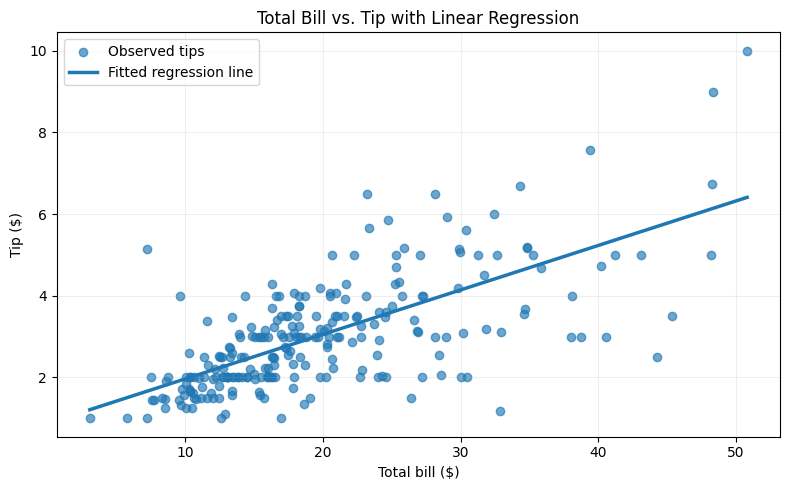

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(X["total_bill"], y, alpha=0.65, label="Observed tips")
line_x = pd.DataFrame({"total_bill": np.linspace(X["total_bill"].min(), X["total_bill"].max(), 200)})
plt.plot(line_x["total_bill"], regression.predict(line_x), linewidth=2.5, label="Fitted regression line")
plt.xlabel("Total bill ($)")
plt.ylabel("Tip ($)")
plt.title("Total Bill vs. Tip with Linear Regression")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Step 5 — Iris 70/30 split**

In [5]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_iris, y_iris, test_size=0.30, random_state=42, stratify=None)
print("Total flowers:", len(X_iris))
print("Training flowers:", len(Xi_train), "| Test flowers:", len(Xi_test))
print("Features:", list(X_iris.columns))

Total flowers: 150
Training flowers: 105 | Test flowers: 45
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


**Step 6 — 5-neighbor kNN (test accuracy)**

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)
print(f"kNN test accuracy: {knn.score(Xi_test, yi_test):.4f}")

kNN test accuracy: 1.0000


**Step 7 — Shallow decision tree and root question**

Shallow tree test accuracy: 1.0000
First question: Is petal length (cm) <= 2.45 cm?


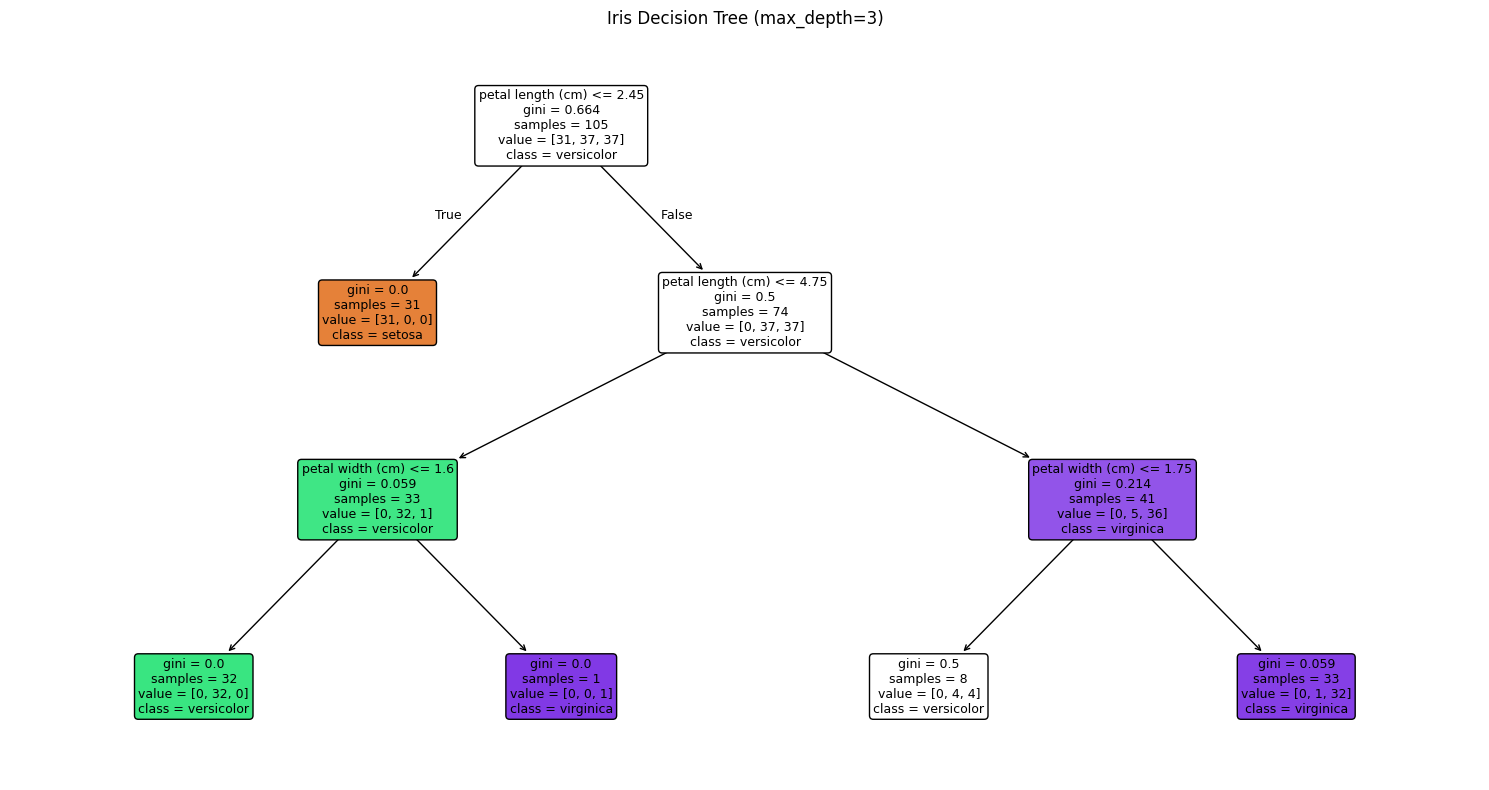

In [7]:
shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
shallow_tree.fit(Xi_train, yi_train)
print(f"Shallow tree test accuracy: {shallow_tree.score(Xi_test, yi_test):.4f}")
root_feature = X_iris.columns[shallow_tree.tree_.feature[0]]
root_threshold = shallow_tree.tree_.threshold[0]
print(f"First question: Is {root_feature} <= {root_threshold:.2f} cm?")
plt.figure(figsize=(15, 8))
plot_tree(shallow_tree, feature_names=list(X_iris.columns), class_names=list(iris.target_names), filled=True, rounded=True, fontsize=9)
plt.title("Iris Decision Tree (max_depth=3)")
plt.tight_layout()
plt.show()

**Root split translation:** The tree checks whether a petal measurement is below a certain cutoff. That first question separates the flowers into two groups, and later branches narrow down the species.

**Step 8 — Overfitting probe**

In [8]:
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(Xi_train, yi_train)
scores = pd.DataFrame({
    "Model": ["Shallow tree (depth=3)", "Unlimited tree"],
    "Train accuracy": [shallow_tree.score(Xi_train, yi_train), full_tree.score(Xi_train, yi_train)],
    "Test accuracy": [shallow_tree.score(Xi_test, yi_test), full_tree.score(Xi_test, yi_test)]
})
print(scores.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

                 Model  Train accuracy  Test accuracy
Shallow tree (depth=3)          0.9524         1.0000
        Unlimited tree          1.0000         1.0000


**Observation:** The unlimited tree is able to fit the training set closely, but that doesn’t make its score on unseen flowers better. The train/test comparison gives a clear picture of whether the model is memorizing the examples.

**Step 9 — Predict a new flower**

In [9]:
new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=X_iris.columns)
new_prediction = int(shallow_tree.predict(new_flower)[0])
print("New flower measurements (cm):")
print(new_flower.to_string(index=False))
print("Predicted species:", iris.target_names[new_prediction])

New flower measurements (cm):
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
               5.9               3.0                5.1               1.8
Predicted species: virginica


**Step 10 — Model report**

This lab used total bill to predict a restaurant tip, and iris flower measurements to predict flower species. The tip regression found an upward relationship between bill size and the expected tip, but real tips vary quite a bit. For the flower task, I would choose the shallow decision tree if its test accuracy is competitive with kNN because I can explain its rules to someone else. The actual accuracy for that tree is 100%, based on the test data. It could fail on flowers with measurements near the border between species or on varieties not shown in this small dataset. If this were a model about people, a risk would be that some groups are missing or underrepresented in the training data, so the predictions may be less reliable or unfair for those groups.

**AI-use appendix**

Tool: ChatGPT. Key prompt: “Build Module 7 Lab 1 with scikit-learn: 70/30 tips regression, iris kNN and shallow/unlimited trees, held-out evaluations, plots, and an honest model report.” Assistance: Python syntax, notebook setup, and initial draft wording. The written reflections were revised by the student.